# Notebook 06 — Advanced Statistical Validation & Robustness Testing

## 1. Introduction

In this notebook, we will evaluate the statistical reliability and robustness of the quantitative event-study results developed in the previous notebooks.

The main objective is to understand whether the observed abnormal returns and cumulative abnormal returns (CAR) represent meaningful market reactions or could simply be random variations.

## 2. Objectives

1. Evaluate event-level statistical significance.
2. Compare results across different event windows.
3. Perform robustness checks on abnormal returns and CAR.
4. Explore out-of-sample validation.
5. Identify potentially overlapping events and confounding factors.
6. Document the limitations and reliability of the findings.

## 3. Important Note

The current pilot dataset contains eight verified earnings events from three companies. Due to this limited sample size, statistical results will be interpreted cautiously. The analysis will distinguish exploratory evidence from statistically reliable conclusions.

In [1]:

from pathlib import Path
import sys
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from sklearn.model_selection import LeaveOneGroupOut

warnings.filterwarnings("ignore")

# Project directory
BASE_DIR = Path.cwd().parent

if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))

DATA_DIR = BASE_DIR / "data"
PROCESSED_DIR = DATA_DIR / "processed"
RESULTS_DIR = DATA_DIR / "results"

print("Libraries imported successfully!")
print("Project directory:", BASE_DIR)
print("Processed directory exists:", PROCESSED_DIR.exists())
print("Results directory exists:", RESULTS_DIR.exists())


Libraries imported successfully!
Project directory: C:\Users\Victus\OneDrive\Desktop\EventEcho_streamlit
Processed directory exists: True
Results directory exists: True


In [2]:

# Load quantitative event-study results

abnormal_df = pd.read_csv(
    RESULTS_DIR / "abnormal_returns.csv"
)

event_car_df = pd.read_csv(
    RESULTS_DIR / "event_car_summary.csv"
)

# Convert date column
abnormal_df["Date"] = pd.to_datetime(
    abnormal_df["Date"],
    errors="coerce"
)

# Display dataset information
print("ABNORMAL RETURNS DATASET")
print("Shape:", abnormal_df.shape)
print("Columns:", abnormal_df.columns.tolist())

print("\nEVENT CAR SUMMARY")
print("Shape:", event_car_df.shape)
print("Columns:", event_car_df.columns.tolist())

print("\nNumber of unique events:",
      abnormal_df["event_id"].nunique())

print("\nNumber of companies:",
      abnormal_df["company"].nunique())

display(event_car_df.head())


ABNORMAL RETURNS DATASET
Shape: (168, 11)
Columns: ['Date', 'AAPL', 'SP500', 'event_id', 'company', 'event_time', 'expected_return', 'abnormal_return', 'MSFT', 'TSLA', 'CAR']

EVENT CAR SUMMARY
Shape: (8, 6)
Columns: ['event_id', 'company', 'total_CAR', 'average_AR', 'max_CAR', 'min_CAR']

Number of unique events: 8

Number of companies: 3


,event_id,company,total_CAR,average_AR,max_CAR,min_CAR
0,EV001,AAPL,-0.737394,-0.035114,-0.737394,-8.933771
1,EV002,AAPL,-1.784097,-0.084957,4.311323,-4.587054
2,EV003,AAPL,9.054650,0.431174,9.222825,-2.652831
3,EV004,MSFT,-4.579524,-0.218073,3.906962,-4.579524
4,EV005,MSFT,7.915669,0.376937,8.992909,-2.697776


In [3]:

# Event-level CAR values
car_values = event_car_df["total_CAR"].dropna()

# Descriptive statistics
car_statistics = {
    "Number of Events": len(car_values),
    "Mean CAR (%)": car_values.mean(),
    "Median CAR (%)": car_values.median(),
    "Standard Deviation": car_values.std(),
    "Minimum CAR (%)": car_values.min(),
    "Maximum CAR (%)": car_values.max()
}

print("EVENT-LEVEL CAR DESCRIPTIVE STATISTICS")
print("-" * 45)

for metric, value in car_statistics.items():
    print(f"{metric}: {value:.4f}")


EVENT-LEVEL CAR DESCRIPTIVE STATISTICS
---------------------------------------------
Number of Events: 8.0000
Mean CAR (%): -0.5118
Median CAR (%): -1.2607
Standard Deviation: 9.1399
Minimum CAR (%): -18.6953
Maximum CAR (%): 9.0547


In [4]:

# Hypothesis testing for event-level CAR

# H0: Mean CAR = 0
# H1: Mean CAR != 0

# One-sample t-test
t_stat, t_pvalue = stats.ttest_1samp(
    car_values,
    popmean=0
)

# Wilcoxon signed-rank test
w_stat, w_pvalue = stats.wilcoxon(
    car_values,
    alternative="two-sided"
)

alpha = 0.05

print("ONE-SAMPLE T-TEST")
print("-" * 40)
print("T-statistic:", round(t_stat, 4))
print("P-value:", round(t_pvalue, 4))

print("\nWILCOXON SIGNED-RANK TEST")
print("-" * 40)
print("W-statistic:", round(w_stat, 4))
print("P-value:", round(w_pvalue, 4))

print("\nSTATISTICAL CONCLUSION")
print("-" * 40)

if t_pvalue < alpha:
    print("T-test: Reject the null hypothesis.")
else:
    print("T-test: Fail to reject the null hypothesis.")

if w_pvalue < alpha:
    print("Wilcoxon: Reject the null hypothesis.")
else:
    print("Wilcoxon: Fail to reject the null hypothesis.")


ONE-SAMPLE T-TEST
----------------------------------------
T-statistic: -0.1584
P-value: 0.8786

WILCOXON SIGNED-RANK TEST
----------------------------------------
W-statistic: 18.0
P-value: 1.0

STATISTICAL CONCLUSION
----------------------------------------
T-test: Fail to reject the null hypothesis.
Wilcoxon: Fail to reject the null hypothesis.


### Interpretation of Event-Level Statistical Tests

The one-sample t-test produced a t-statistic of -0.1584 and a p-value of 0.8786. The Wilcoxon signed-rank test produced a statistic of 18.0 and a p-value of 1.0000.

Both p-values are greater than the selected significance level of 0.05. Therefore, we fail to reject the null hypothesis that the event-level CAR is centered around zero under the respective test assumptions.

These results indicate that the current sample does not provide sufficient statistical evidence of a non-zero average cumulative abnormal return.

However, this does not establish that market reactions are absent. The analysis contains only eight events, and the substantial variation in CAR values limits the statistical power and generalisability of the findings.

Further analysis using alternative event windows, robustness checks, and a larger verified event sample is required.

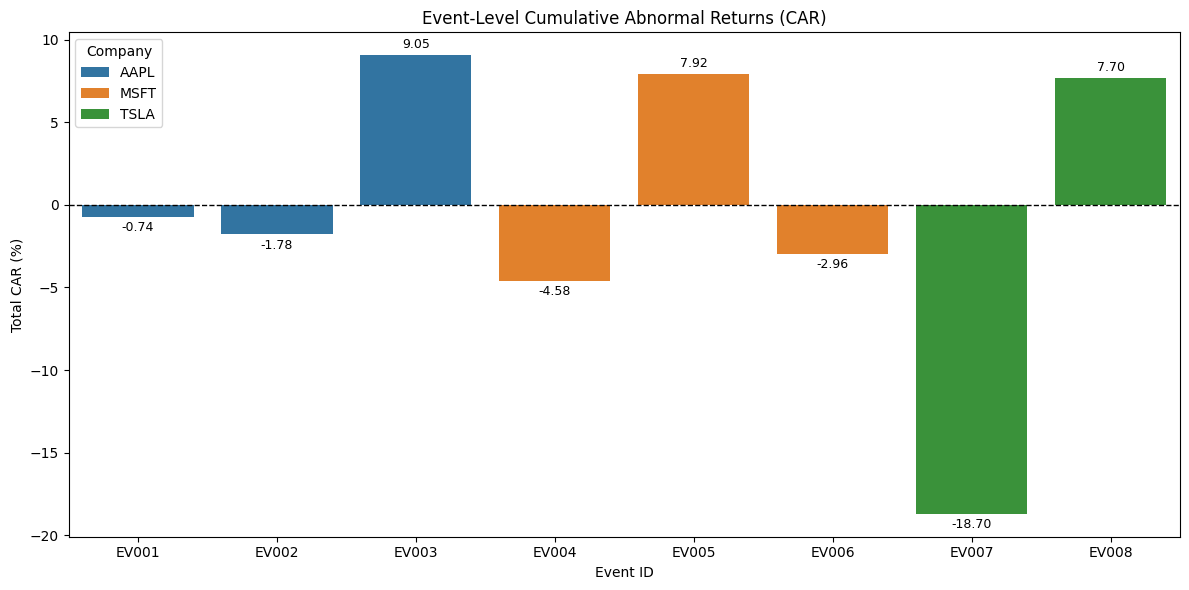

In [6]:
plt.figure(figsize=(12, 6))

ax = sns.barplot(
    data=event_car_df,
    x="event_id",
    y="total_CAR",
    hue="company",
    dodge=False
)

ax.axhline(0, color="black", linestyle="--", linewidth=1)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f",
        padding=3,
        fontsize=9
    )

plt.title("Event-Level Cumulative Abnormal Returns (CAR)")
plt.xlabel("Event ID")
plt.ylabel("Total CAR (%)")
plt.legend(title="Company")
plt.tight_layout()
plt.show()

In [7]:

# Load event-window CAR matrix from Notebook 02

window_car_df = pd.read_csv(
    RESULTS_DIR / "event_window_car_matrix.csv"
)

print("Dataset shape:", window_car_df.shape)
print("\nColumns:")
print(window_car_df.columns.tolist())

display(window_car_df.head(10))


Dataset shape: (8, 6)

Columns:
['event_id', '[-1, +1]', '[0, +1]', '[-5, +5]', '[-10, +10]', 'company']


,event_id,"[-1, +1]","[0, +1]","[-5, +5]","[-10, +10]",company
0,EV001,-4.486363,-3.242996,2.171741,-0.737394,AAPL
1,EV002,-7.787734,-7.626301,-7.622040,-1.784097,AAPL
2,EV003,-1.711975,-1.630623,7.906609,9.054650,AAPL
3,EV004,-6.597412,-6.071619,-6.108006,-4.579524,MSFT
4,EV005,8.035610,7.838596,11.079116,7.915669,MSFT
5,EV006,3.771258,3.686672,1.522433,-2.964244,MSFT
6,EV007,-6.912409,-3.295403,0.738697,-18.695251,TSLA
7,EV008,-7.269767,-5.646598,-5.858372,7.695698,TSLA


In [8]:

# Identify event window columns
window_columns = [
    "[-1, +1]",
    "[0, +1]",
    "[-5, +5]",
    "[-10, +10]"
]

# Calculate statistics for each event window
window_statistics = []

for window in window_columns:

    values = window_car_df[window].dropna()

    window_statistics.append({
        "Event_Window": window,
        "Mean_CAR": values.mean(),
        "Median_CAR": values.median(),
        "Std_Deviation": values.std(),
        "Positive_Events": (values > 0).sum(),
        "Negative_Events": (values < 0).sum()
    })

window_stats_df = pd.DataFrame(window_statistics)

print("EVENT WINDOW COMPARISON")
display(window_stats_df.round(4))


EVENT WINDOW COMPARISON


,Event_Window,Mean_CAR,Median_CAR,Std_Deviation,Positive_Events,Negative_Events
0,"[-1, +1]",-2.8698,-5.5419,5.8648,2,6
1,"[0, +1]",-1.9985,-3.2692,5.2648,2,6
2,"[-5, +5]",0.4788,1.1306,6.7690,5,3
3,"[-10, +10]",-0.5118,-1.2607,9.1399,3,5


In [9]:

# Friedman test for repeated event-window measurements

friedman_stat, friedman_pvalue = stats.friedmanchisquare(
    window_car_df["[-1, +1]"],
    window_car_df["[0, +1]"],
    window_car_df["[-5, +5]"],
    window_car_df["[-10, +10]"]
)

alpha = 0.05

print("FRIEDMAN TEST")
print("-" * 40)

print("Test Statistic:", round(friedman_stat, 4))
print("P-value:", round(friedman_pvalue, 4))

print("\nCONCLUSION")
print("-" * 40)

if friedman_pvalue < alpha:
    print("Reject the null hypothesis.")
    print("At least one event window shows a different distribution.")
else:
    print("Fail to reject the null hypothesis.")
    print("No statistically significant difference detected.")


FRIEDMAN TEST
----------------------------------------
Test Statistic: 4.65
P-value: 0.1993

CONCLUSION
----------------------------------------
Fail to reject the null hypothesis.
No statistically significant difference detected.


### Interpretation of Friedman Test

The Friedman test was performed to compare cumulative abnormal returns across four event windows: (-1,+1), (0,+1), (-5,+5), and (-10,+10).

The test produced a Friedman statistic of 4.65 and a p-value of 0.1993.

Since the p-value is greater than the significance level of 0.05, we fail to reject the null hypothesis.

Although the average CAR values differ across the selected event windows, the test does not provide sufficient statistical evidence of systematic differences in their distributions.

This result does not establish that the event windows are equivalent. The small sample of eight events may limit the statistical power of the test.

Therefore, the sensitivity of CAR to event-window selection remains an important consideration in interpreting the event-study results.

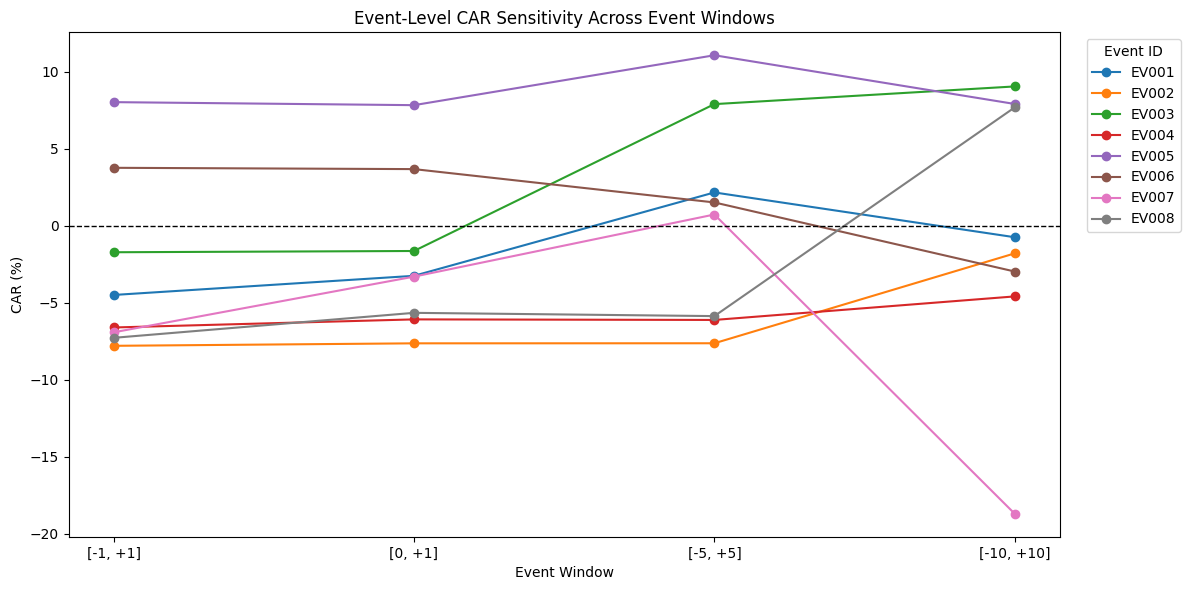

In [10]:

plt.figure(figsize=(12, 6))

for _, row in window_car_df.iterrows():
    plt.plot(
        window_columns,
        [row[window] for window in window_columns],
        marker="o",
        linewidth=1.5,
        label=row["event_id"]
    )

plt.axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

plt.title("Event-Level CAR Sensitivity Across Event Windows")
plt.xlabel("Event Window")
plt.ylabel("CAR (%)")
plt.legend(title="Event ID", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


### Event-Window Sensitivity Analysis

The event-window sensitivity analysis compares cumulative abnormal returns across four different event windows for eight verified earnings events.

The results show considerable variation in CAR across different windows. Some events, such as EV003 and EV008, change their CAR direction when the event window is extended. EV007 exhibits a particularly large negative CAR in the (-10,+10) window.

These observations indicate that the measured cumulative abnormal return can be sensitive to event-window selection.

However, longer event windows may include unrelated market movements, overlapping announcements, and other confounding factors. Therefore, changes in CAR should not automatically be attributed to the original earnings announcement.

The Friedman test did not detect statistically significant differences across the four windows (p-value = 0.1993). Given the small sample size, this result should be interpreted cautiously.

In [11]:

# Load historical market data

prices_df = pd.read_csv(
    PROCESSED_DIR / "pilot_closing_prices.csv"
)

returns_df = pd.read_csv(
    PROCESSED_DIR / "pilot_daily_returns.csv"
)

# Convert dates
prices_df["Date"] = pd.to_datetime(prices_df["Date"])
returns_df["Date"] = pd.to_datetime(returns_df["Date"])

# Sort chronologically
prices_df = prices_df.sort_values("Date").reset_index(drop=True)
returns_df = returns_df.sort_values("Date").reset_index(drop=True)

print("CLOSING PRICES")
print("Shape:", prices_df.shape)
print("Date range:", prices_df["Date"].min(), "to", prices_df["Date"].max())

print("\nDAILY RETURNS")
print("Shape:", returns_df.shape)
print("Date range:", returns_df["Date"].min(), "to", returns_df["Date"].max())

print("\nAvailable columns:")
print(returns_df.columns.tolist())

display(returns_df.head())


CLOSING PRICES
Shape: (293, 5)
Date range: 2024-07-01 00:00:00 to 2025-08-29 00:00:00

DAILY RETURNS
Shape: (293, 5)
Date range: 2024-07-01 00:00:00 to 2025-08-29 00:00:00

Available columns:
['Date', 'AAPL', 'MSFT', 'TSLA', 'SP500']


,Date,AAPL,MSFT,TSLA,SP500
0,2024-07-01,NaN,NaN,NaN,NaN
1,2024-07-02,1.624016,0.558303,10.197271,0.619532
2,2024-07-03,0.581091,0.324431,6.542422,0.508444
3,2024-07-05,2.162031,1.473610,2.082067,0.544877
4,2024-07-08,0.653901,-0.282327,0.564567,0.101670


In [12]:

# Remove rows with missing return values
market_data = returns_df.dropna(
    subset=["AAPL", "MSFT", "TSLA", "SP500"]
).copy()

# Ensure chronological order
market_data = market_data.sort_values("Date").reset_index(drop=True)

# 80-20 chronological split
split_index = int(len(market_data) * 0.80)

train_df = market_data.iloc[:split_index].copy()
test_df = market_data.iloc[split_index:].copy()

print("CHRONOLOGICAL TRAIN-TEST SPLIT")
print("-" * 45)

print("Total observations:", len(market_data))

print("\nTRAINING DATA")
print("Observations:", len(train_df))
print("Start date:", train_df["Date"].min())
print("End date:", train_df["Date"].max())

print("\nTESTING DATA")
print("Observations:", len(test_df))
print("Start date:", test_df["Date"].min())
print("End date:", test_df["Date"].max())

print("\nMissing values in training:", train_df.isnull().sum().sum())
print("Missing values in testing:", test_df.isnull().sum().sum())


CHRONOLOGICAL TRAIN-TEST SPLIT
---------------------------------------------
Total observations: 292

TRAINING DATA
Observations: 233
Start date: 2024-07-02 00:00:00
End date: 2025-06-05 00:00:00

TESTING DATA
Observations: 59
Start date: 2025-06-06 00:00:00
End date: 2025-08-29 00:00:00

Missing values in training: 0
Missing values in testing: 0


In [13]:

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

companies = ["AAPL", "MSFT", "TSLA"]

market_models = {}
prediction_results = []
model_metrics = []

for company in companies:

    # Prepare training data
    X_train = train_df[["SP500"]]
    y_train = train_df[company]

    # Prepare testing data
    X_test = test_df[["SP500"]]
    y_test = test_df[company]

    # Train market model
    model = LinearRegression()
    model.fit(X_train, y_train)

    # Predict unseen stock returns
    y_pred = model.predict(X_test)

    market_models[company] = model

    # Store predictions
    company_predictions = pd.DataFrame({
        "Date": test_df["Date"].values,
        "Company": company,
        "Actual_Return": y_test.values,
        "Predicted_Return": y_pred
    })

    prediction_results.append(company_predictions)

    # Calculate test metrics
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)

    model_metrics.append({
        "Company": company,
        "Alpha": model.intercept_,
        "Beta": model.coef_[0],
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

# Combine results
predictions_df = pd.concat(
    prediction_results,
    ignore_index=True
)

metrics_df = pd.DataFrame(model_metrics)

print("MARKET MODEL TRAINING COMPLETED")
display(metrics_df.round(4))

print("Prediction dataset shape:", predictions_df.shape)
display(predictions_df.head())


MARKET MODEL TRAINING COMPLETED


,Company,Alpha,Beta,MAE,RMSE,R2
0,AAPL,-0.0638,1.2464,0.8183,1.1777,0.2561
1,MSFT,-0.0151,0.9733,0.6129,0.8554,0.2313
2,TSLA,0.1345,2.5093,2.2562,2.7682,0.1690


Prediction dataset shape: (177, 4)


,Date,Company,Actual_Return,Predicted_Return
0,2025-06-06,AAPL,1.639839,1.217539
1,2025-06-09,AAPL,-1.211264,0.050851
2,2025-06-10,AAPL,0.605614,0.619572
3,2025-06-11,AAPL,-1.919378,-0.405796
4,2025-06-12,AAPL,0.211283,0.412605


In [14]:

baseline_results = []

for company in companies:

    # Predict every test observation using training mean
    baseline_prediction = np.repeat(
        train_df[company].mean(),
        len(test_df)
    )

    actual_returns = test_df[company]

    # Baseline metrics
    baseline_mae = mean_absolute_error(
        actual_returns,
        baseline_prediction
    )

    baseline_rmse = np.sqrt(
        mean_squared_error(actual_returns, baseline_prediction)
    )

    baseline_r2 = r2_score(
        actual_returns,
        baseline_prediction
    )

    # Market model metrics
    model_prediction = market_models[company].predict(
        test_df[["SP500"]]
    )

    model_mae = mean_absolute_error(
        actual_returns,
        model_prediction
    )

    model_rmse = np.sqrt(
        mean_squared_error(actual_returns, model_prediction)
    )

    model_r2 = r2_score(
        actual_returns,
        model_prediction
    )

    baseline_results.append({
        "Company": company,
        "Baseline_MAE": baseline_mae,
        "Market_Model_MAE": model_mae,
        "Baseline_RMSE": baseline_rmse,
        "Market_Model_RMSE": model_rmse,
        "Baseline_R2": baseline_r2,
        "Market_Model_R2": model_r2
    })

baseline_comparison_df = pd.DataFrame(baseline_results)

display(baseline_comparison_df.round(4))


,Company,Baseline_MAE,Market_Model_MAE,Baseline_RMSE,Market_Model_RMSE,Baseline_R2,Market_Model_R2
0,AAPL,0.9830,0.8183,1.3917,1.1777,-0.0387,0.2561
1,MSFT,0.7292,0.6129,0.9826,0.8554,-0.0143,0.2313
2,TSLA,2.3447,2.2562,3.0376,2.7682,-0.0006,0.1690


### Baseline Model vs Market Model Comparison

The performance of the Market Model was compared against a baseline model that predicts the mean stock return calculated from the training dataset.

The Market Model achieved lower MAE and RMSE values and higher R² values for all three companies: AAPL, MSFT, and TSLA.

This indicates that incorporating S&P 500 market returns provides an improvement in expected-return estimation compared with the historical-mean baseline over the selected testing period.

However, the improvement is relatively modest, especially for TSLA. The results are based on a single chronological test period and should not be interpreted as proof of consistent future predictive performance.

Further validation across different time periods is required.

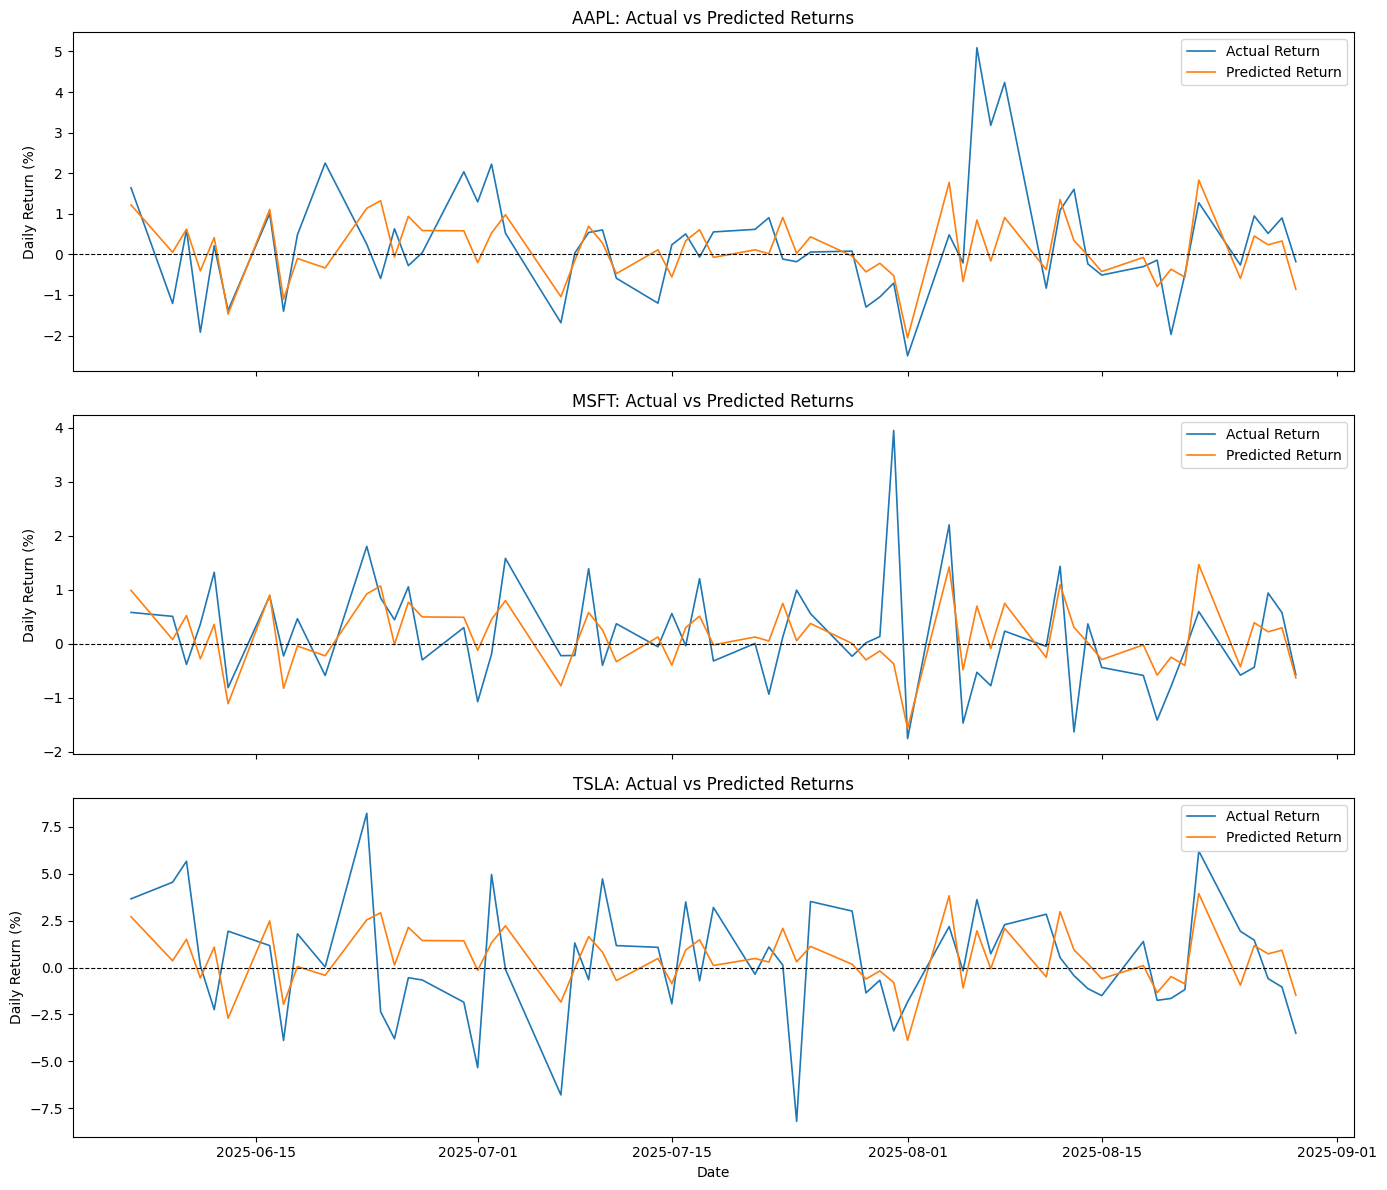

In [15]:

fig, axes = plt.subplots(
    3, 1,
    figsize=(14, 12),
    sharex=True
)

for ax, company in zip(axes, companies):

    company_data = predictions_df[
        predictions_df["Company"] == company
    ].copy()

    ax.plot(
        company_data["Date"],
        company_data["Actual_Return"],
        label="Actual Return",
        linewidth=1.2
    )

    ax.plot(
        company_data["Date"],
        company_data["Predicted_Return"],
        label="Predicted Return",
        linewidth=1.2
    )

    ax.axhline(0, color="black", linestyle="--", linewidth=0.8)

    ax.set_title(f"{company}: Actual vs Predicted Returns")
    ax.set_ylabel("Daily Return (%)")
    ax.legend()

plt.xlabel("Date")
plt.tight_layout()
plt.show()


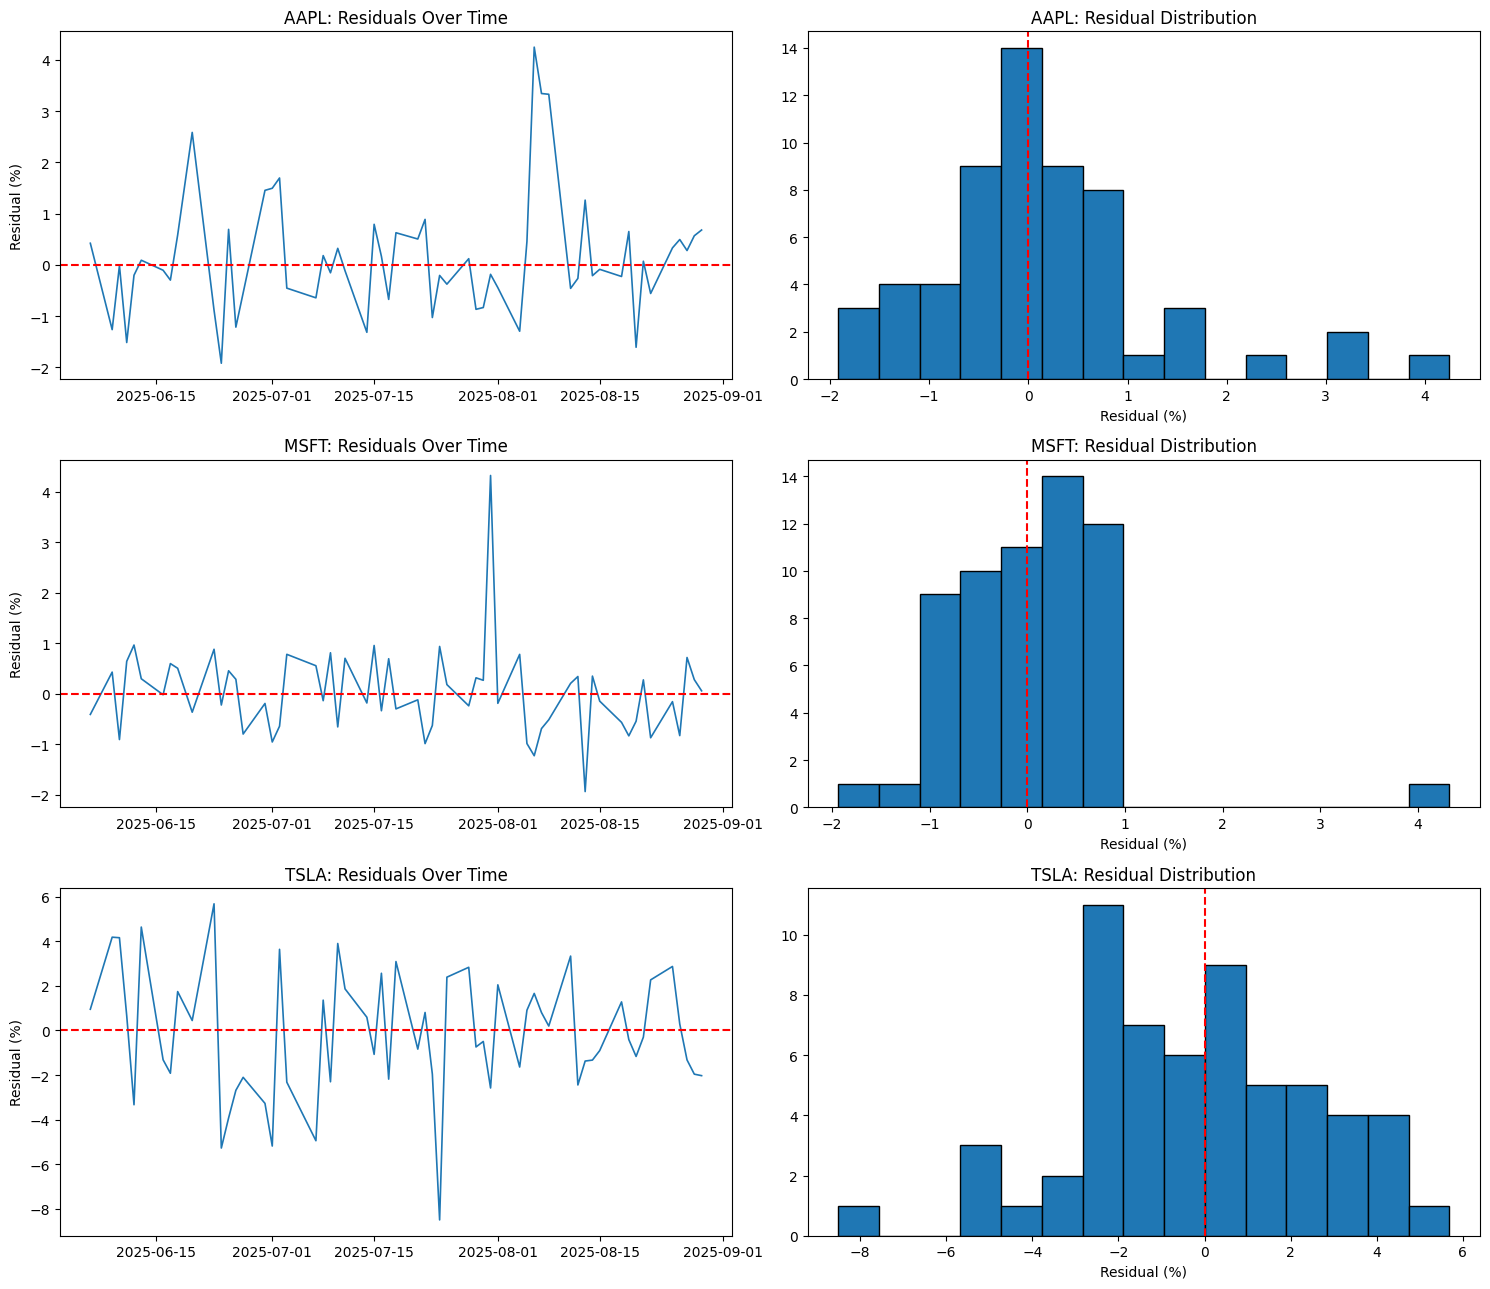

In [16]:

# Calculate prediction residuals
predictions_df["Residual"] = (
    predictions_df["Actual_Return"] -
    predictions_df["Predicted_Return"]
)

fig, axes = plt.subplots(3, 2, figsize=(15, 13))

for i, company in enumerate(companies):

    company_data = predictions_df[
        predictions_df["Company"] == company
    ].copy()

    # Residuals over time
    axes[i, 0].plot(
        company_data["Date"],
        company_data["Residual"],
        linewidth=1.2
    )

    axes[i, 0].axhline(0, color="red", linestyle="--")
    axes[i, 0].set_title(f"{company}: Residuals Over Time")
    axes[i, 0].set_ylabel("Residual (%)")

    # Residual distribution
    axes[i, 1].hist(
        company_data["Residual"],
        bins=15,
        edgecolor="black"
    )

    axes[i, 1].axvline(0, color="red", linestyle="--")
    axes[i, 1].set_title(f"{company}: Residual Distribution")
    axes[i, 1].set_xlabel("Residual (%)")

plt.tight_layout()
plt.show()


In [17]:

residual_diagnostics = []

for company in companies:

    company_residuals = predictions_df.loc[
        predictions_df["Company"] == company,
        "Residual"
    ].dropna()

    shapiro_stat, shapiro_p = stats.shapiro(company_residuals)

    residual_diagnostics.append({
        "Company": company,
        "Mean_Residual": company_residuals.mean(),
        "Std_Residual": company_residuals.std(),
        "Skewness": stats.skew(company_residuals),
        "Kurtosis": stats.kurtosis(company_residuals),
        "Shapiro_Statistic": shapiro_stat,
        "Shapiro_p_value": shapiro_p
    })

residual_diagnostics_df = pd.DataFrame(residual_diagnostics)

display(residual_diagnostics_df.round(4))


,Company,Mean_Residual,Std_Residual,Skewness,Kurtosis,Shapiro_Statistic,Shapiro_p_value
0,AAPL,0.1425,1.1791,1.3022,2.4394,0.9012,0.0002
1,MSFT,0.0179,0.8625,1.8615,8.7960,0.8482,0.0000
2,TSLA,-0.1804,2.7861,-0.2666,0.1560,0.9848,0.6689


In [20]:
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan

heteroskedasticity_results = []

for company in companies:

    company_data = predictions_df[
        predictions_df["Company"] == company
    ].copy()

    residuals = company_data["Residual"]

    # Market return as explanatory variable
    market_returns = test_df["SP500"].values

    # Add intercept
    X = sm.add_constant(market_returns)

    bp_stat, bp_pvalue, f_stat, f_pvalue = het_breuschpagan(
        residuals,
        X
    )

    heteroskedasticity_results.append({
        "Company": company,
        "BP_Statistic": bp_stat,
        "BP_p_value": bp_pvalue,
        "F_Statistic": f_stat,
        "F_p_value": f_pvalue
    })

heteroskedasticity_df = pd.DataFrame(
    heteroskedasticity_results
)

display(heteroskedasticity_df.round(4))


,Company,BP_Statistic,BP_p_value,F_Statistic,F_p_value
0,AAPL,1.6340,0.2012,1.6235,0.2078
1,MSFT,0.3212,0.5709,0.3120,0.5786
2,TSLA,0.0646,0.7993,0.0625,0.8035


In [21]:

# Combine model performance and residual diagnostics

final_validation_df = metrics_df.merge(
    baseline_comparison_df,
    on="Company"
)

final_validation_df = final_validation_df.merge(
    residual_diagnostics_df,
    on="Company"
)

final_validation_df = final_validation_df.merge(
    heteroskedasticity_df,
    on="Company"
)

# Save final validation results
output_path = RESULTS_DIR / "advanced_model_validation.csv"

final_validation_df.to_csv(output_path, index=False)

print("Final validation file saved successfully!")
print("File:", output_path)
print("Shape:", final_validation_df.shape)

display(final_validation_df.round(4))


Final validation file saved successfully!
File: C:\Users\Victus\OneDrive\Desktop\EventEcho_streamlit\data\results\advanced_model_validation.csv
Shape: (3, 22)


,Company,Alpha,Beta,MAE,RMSE,R2,Baseline_MAE,Market_Model_MAE,Baseline_RMSE,Market_Model_RMSE,...,Mean_Residual,Std_Residual,Skewness,Kurtosis,Shapiro_Statistic,Shapiro_p_value,BP_Statistic,BP_p_value,F_Statistic,F_p_value
0,AAPL,-0.0638,1.2464,0.8183,1.1777,0.2561,0.9830,0.8183,1.3917,1.1777,...,0.1425,1.1791,1.3022,2.4394,0.9012,0.0002,1.6340,0.2012,1.6235,0.2078
1,MSFT,-0.0151,0.9733,0.6129,0.8554,0.2313,0.7292,0.6129,0.9826,0.8554,...,0.0179,0.8625,1.8615,8.7960,0.8482,0.0000,0.3212,0.5709,0.3120,0.5786
2,TSLA,0.1345,2.5093,2.2562,2.7682,0.1690,2.3447,2.2562,3.0376,2.7682,...,-0.1804,2.7861,-0.2666,0.1560,0.9848,0.6689,0.0646,0.7993,0.0625,0.8035


## Conclusion — Advanced Statistical Validation

In this notebook, we evaluated the reliability and predictive performance of the Market Model using statistical tests and chronological out-of-sample validation.

The event-level CAR analysis showed no statistically significant difference from zero. Similarly, the Friedman test did not identify significant differences across the selected event windows.

For out-of-sample validation, the dataset was divided chronologically into 80% training data and 20% testing data. The Market Model outperformed the historical-mean baseline in terms of MAE and RMSE for AAPL, MSFT, and TSLA. However, the R² values remained relatively low, indicating that market returns explain only a limited portion of individual stock-return variation.

Residual diagnostics showed different characteristics across companies. AAPL and MSFT residuals rejected the normality assumption, while TSLA residuals did not. The Breusch-Pagan tests found no statistically significant evidence of heteroskedasticity with respect to market returns.

### Key Limitations

- The analysis includes only eight verified earnings events across three companies.
- Out-of-sample validation uses a single chronological test period.
- Residual normality was not supported for AAPL and MSFT.
- The Market Model does not capture all company-specific movements.
- Potential confounding events and overlapping announcements cannot be completely excluded.
- Statistical association does not establish causation or guarantee profitable trading strategies.

### Final Conclusion

The Market Model provides a useful benchmark for estimating expected stock returns and calculating abnormal returns. The validation results support its use as an exploratory event-study framework, but the limited sample size and predictive performance restrict the strength and generalisability of the conclusions.

Further research with a larger set of verified corporate events, multiple companies, alternative benchmarks, and repeated out-of-sample validation would improve the reliability of the platform.